## Task 1: Hard-Margin and Soft-Margin SVM

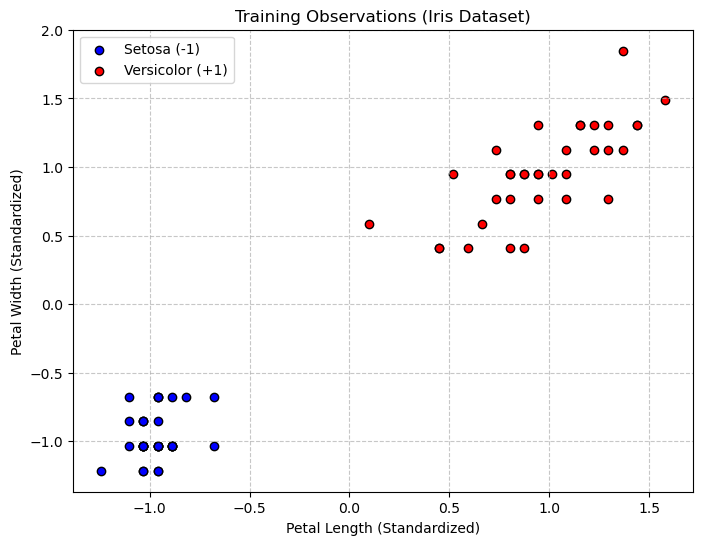

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


iris = load_iris()
X = iris.data
y = iris.target

mask = (y == 0) | (y == 1)
X = X[mask]
y = y[mask]

X = X[:, 2:4]

y = np.where(y == 0, -1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
            color='blue', label='Setosa (-1)', edgecolors='k')
plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
            color='red', label='Versicolor (+1)', edgecolors='k')
plt.xlabel('Petal Length (Standardized)')
plt.ylabel('Petal Width (Standardized)')
plt.title('Training Observations (Iris Dataset)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## A. Hard-Margin Approximation

Training Accuracy: 1.0000
Test Accuracy: 1.0000
Number of Support Vectors: 2
Margin Width (M): 1.4810
All hard-margin constraints satisfied (within 0.001 tolerance).


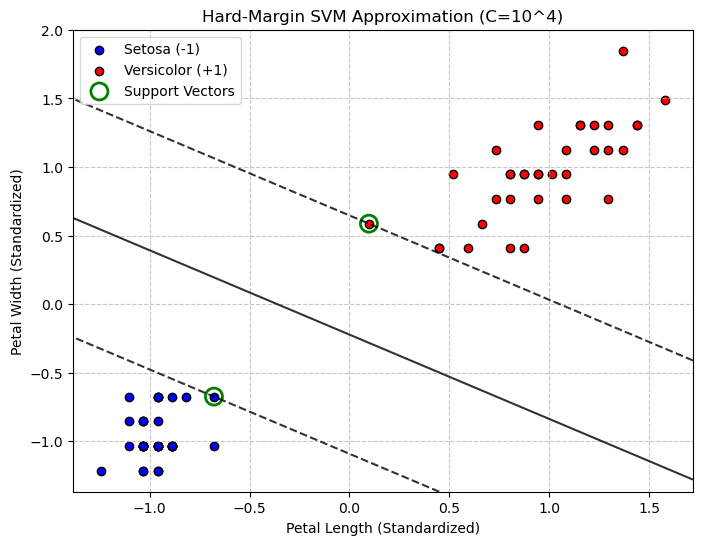

In [2]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

svm_hard = SVC(kernel="linear", C=1e4, random_state=42)
svm_hard.fit(X_train_scaled, y_train)

y_train_pred = svm_hard.predict(X_train_scaled)
y_test_pred = svm_hard.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

n_support_vectors = len(svm_hard.support_vectors_)
print(f"Number of Support Vectors: {n_support_vectors}")

w = svm_hard.coef_[0]
w_norm = np.linalg.norm(w)
margin_width = 2 / w_norm
print(f"Margin Width (M): {margin_width:.4f}")

decision_scores = svm_hard.decision_function(X_train_scaled)
constraints = y_train * decision_scores
tolerance = 1e-3

violations = np.sum(constraints < (1 - tolerance))
if violations == 0:
    print(f"All hard-margin constraints satisfied (within {tolerance} tolerance).")
else:
    print(f"Number of constraint violations: {violations}")

plt.figure(figsize=(8, 6))

plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
            color='blue', label='Setosa (-1)', edgecolors='k')
plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
            color='red', label='Versicolor (+1)', edgecolors='k')

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 50)
yy = np.linspace(ylim[0], ylim[1], 50)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = svm_hard.decision_function(xy).reshape(XX.shape)

ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
           linestyles=['--', '-', '--'])

ax.scatter(svm_hard.support_vectors_[:, 0], svm_hard.support_vectors_[:, 1], s=150,
           linewidth=2, facecolors='none', edgecolors='green', label='Support Vectors')

plt.xlabel('Petal Length (Standardized)')
plt.ylabel('Petal Width (Standardized)')
plt.title('Hard-Margin SVM Approximation (C=10^4)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## B. Soft-Margin SVM

C = 0.1
Training Accuracy: 1.0000 | Test Accuracy: 1.0000
Margin Width: 2.0542 | Support Vectors: 12


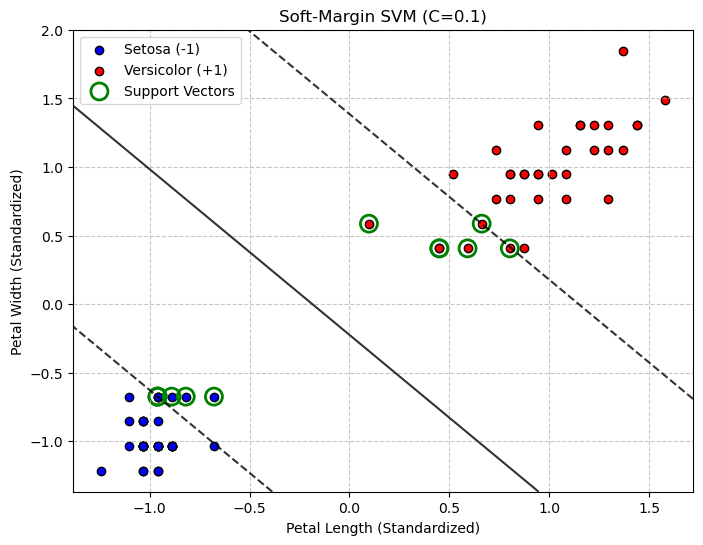

--------------------------------------------------
C = 1
Training Accuracy: 1.0000 | Test Accuracy: 1.0000
Margin Width: 1.4810 | Support Vectors: 2


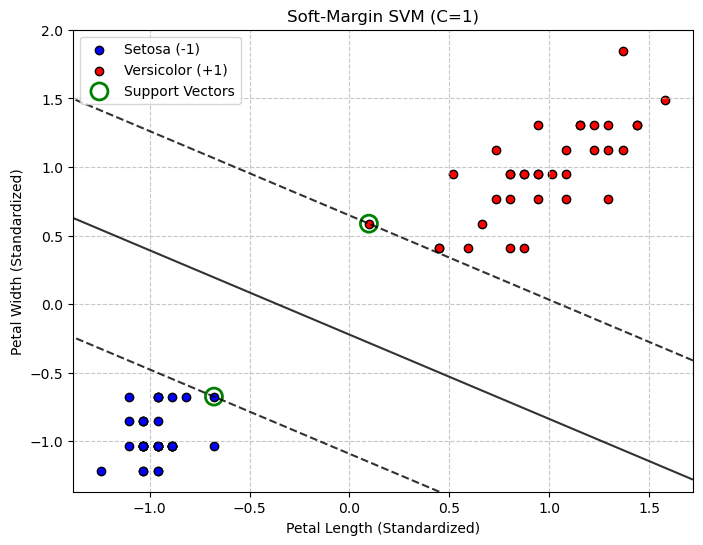

--------------------------------------------------
C = 10
Training Accuracy: 1.0000 | Test Accuracy: 1.0000
Margin Width: 1.4810 | Support Vectors: 2


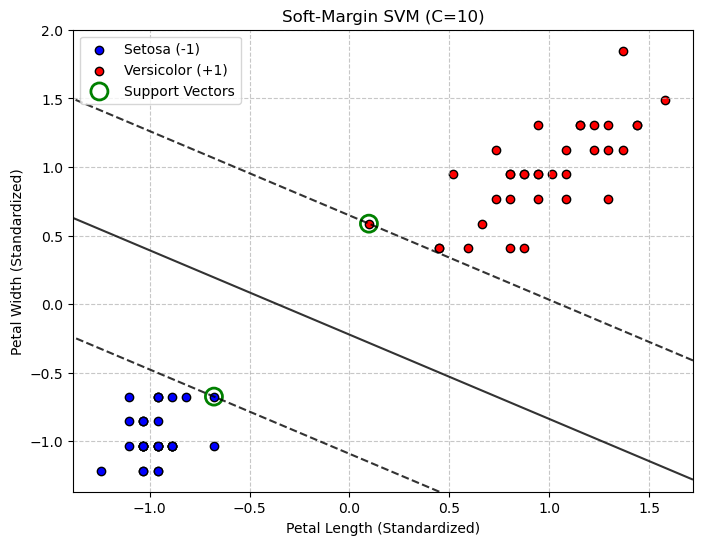

--------------------------------------------------


In [3]:
C_values = [0.1, 1, 10]

for c in C_values:
    svm_soft = SVC(kernel="linear", C=c, random_state=42)
    svm_soft.fit(X_train_scaled, y_train)
    
    y_train_pred = svm_soft.predict(X_train_scaled)
    y_test_pred = svm_soft.predict(X_test_scaled)
    
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    
    n_support_vectors = len(svm_soft.support_vectors_)
    
    w = svm_soft.coef_[0]
    margin_width = 2 / np.linalg.norm(w)
    
    print(f"C = {c}")
    print(f"Training Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
    print(f"Margin Width: {margin_width:.4f} | Support Vectors: {n_support_vectors}")
    
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
                color='blue', label='Setosa (-1)', edgecolors='k')
    plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
                color='red', label='Versicolor (+1)', edgecolors='k')
    
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 50)
    yy = np.linspace(ylim[0], ylim[1], 50)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = svm_soft.decision_function(xy).reshape(XX.shape)
    
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
               linestyles=['--', '-', '--'])
    
    ax.scatter(svm_soft.support_vectors_[:, 0], svm_soft.support_vectors_[:, 1], s=150,
               linewidth=2, facecolors='none', edgecolors='green', label='Support Vectors')
    
    plt.xlabel('Petal Length (Standardized)')
    plt.ylabel('Petal Width (Standardized)')
    plt.title(f'Soft-Margin SVM (C={c})')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
    print("-" * 50)

In [4]:
import pandas as pd

task1_summary = []
all_C = [0.1, 1, 10, 1e4]

for c in all_C:
    clf = SVC(kernel="linear", C=c, random_state=42)
    clf.fit(X_train_scaled, y_train)
    tr_acc = accuracy_score(y_train, clf.predict(X_train_scaled))
    te_acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    mw = 2 / np.linalg.norm(clf.coef_[0])
    n_sv = len(clf.support_vectors_)
    c_label = "10^4 (Hard-Margin Approx)" if c == 1e4 else str(c)
    task1_summary.append({
        "C": c_label,
        "Training Accuracy": f"{tr_acc:.4f}",
        "Test Accuracy": f"{te_acc:.4f}",
        "Margin Width": f"{mw:.4f}",
        "Support Vectors": n_sv
    })

df_task1 = pd.DataFrame(task1_summary)
print("--- Task 1 Summary: Hard-Margin vs Soft-Margin SVM ---")
print(df_task1.to_string(index=False))

--- Task 1 Summary: Hard-Margin vs Soft-Margin SVM ---
                        C Training Accuracy Test Accuracy Margin Width  Support Vectors
                      0.1            1.0000        1.0000       2.0542               12
                        1            1.0000        1.0000       1.4810                2
                       10            1.0000        1.0000       1.4810                2
10^4 (Hard-Margin Approx)            1.0000        1.0000       1.4810                2


### Observations:
- **Linear Separability**: The Setosa and Versicolor classes are completely linearly separable when projected onto the standardized petal length and petal width feature space, creating a distinct empty gap between the two classes.
- **Hard-Margin Approximation ($C=10^4$)**: The hard-margin formulation with $C=10^4$ achieves 100% training and test accuracy with zero constraint violations within the numerical tolerance of $10^{-3}$. It yields a margin width $M = 1.4810$ and relies strictly on only $2$ support vectors (one sample from Setosa and one from Versicolor) that lie directly on the canonical margin hyperplanes $w^T x + b = \pm 1$.
- **Effect of Regularization Parameter $C$**: The parameter $C$ controls the trade-off between maximizing the margin width and penalizing margin violations. 
  - For small $C = 0.1$, the penalty on the slack variables is mild, leading to a significantly wider margin ($M = 2.0542$) and recruiting $12$ support vectors inside or on the margin boundary.
  - As $C$ increases to $1, 10$, and $10^4$, the penalty on margin intrusion grows large, causing the margin width to narrow down to the hard-margin limit ($M = 1.4810$) and reducing the number of support vectors down to the minimal set of $2$ boundary points.

## Task 2: Robustness to Outliers

Original Training Samples: 70
Introduced Contradictory Samples: 10
Modified Training Samples: 80


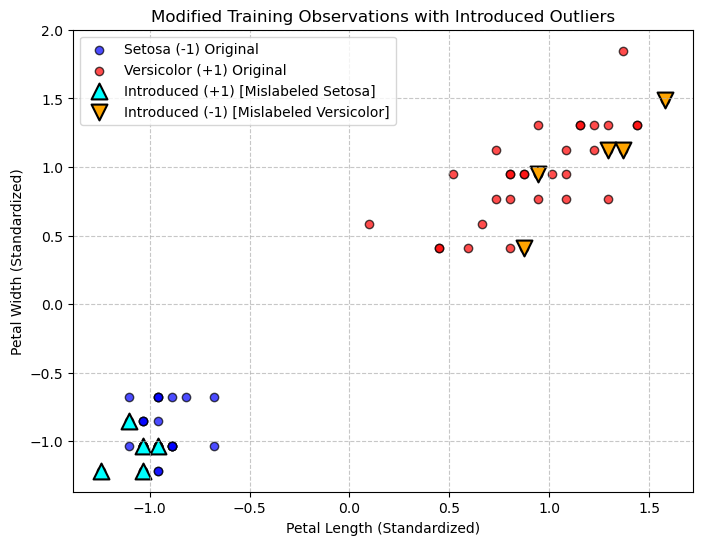

In [5]:
np.random.seed(42)

idx_neg = np.where(y_train == -1)[0]
idx_pos = np.where(y_train == 1)[0]

chosen_neg = np.random.choice(idx_neg, 5, replace=False)
chosen_pos = np.random.choice(idx_pos, 5, replace=False)

outliers_X = np.vstack([X_train_scaled[chosen_neg], X_train_scaled[chosen_pos]])
outliers_y = np.array([1] * 5 + [-1] * 5)

X_train_mod = np.vstack([X_train_scaled, outliers_X])
y_train_mod = np.concatenate([y_train, outliers_y])

print(f"Original Training Samples: {len(X_train_scaled)}")
print(f"Introduced Contradictory Samples: {len(outliers_X)}")
print(f"Modified Training Samples: {len(X_train_mod)}")

plt.figure(figsize=(8, 6))

plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
            color='blue', label='Setosa (-1) Original', edgecolors='k', alpha=0.7)
plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
            color='red', label='Versicolor (+1) Original', edgecolors='k', alpha=0.7)

plt.scatter(outliers_X[outliers_y == 1, 0], outliers_X[outliers_y == 1, 1], 
            color='cyan', marker='^', s=130, edgecolors='k', linewidth=1.5, 
            label='Introduced (+1) [Mislabeled Setosa]')
plt.scatter(outliers_X[outliers_y == -1, 0], outliers_X[outliers_y == -1, 1], 
            color='orange', marker='v', s=130, edgecolors='k', linewidth=1.5, 
            label='Introduced (-1) [Mislabeled Versicolor]')

plt.xlabel('Petal Length (Standardized)')
plt.ylabel('Petal Width (Standardized)')
plt.title('Modified Training Observations with Introduced Outliers')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## A. Large-C Linear SVM

Large-C (C=10^4) Linear SVM on Modified Training Data:
Training Accuracy: 0.8750
Clean-Test Accuracy: 1.0000
Number of Support Vectors: 29
Training Observations Violating Margin (y * f(x) < 1): 30


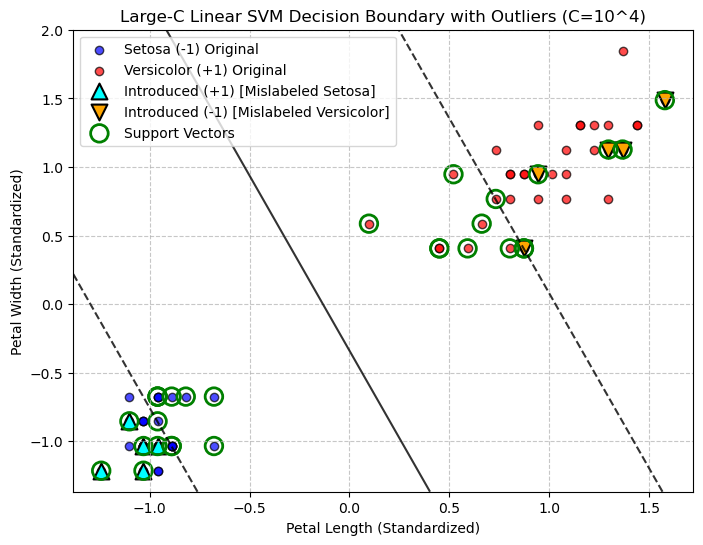

In [6]:
svm_mod_hard = SVC(kernel="linear", C=1e4, random_state=42)
svm_mod_hard.fit(X_train_mod, y_train_mod)

y_train_mod_pred = svm_mod_hard.predict(X_train_mod)
y_clean_test_pred = svm_mod_hard.predict(X_test_scaled)

train_acc = accuracy_score(y_train_mod, y_train_mod_pred)
test_acc = accuracy_score(y_test, y_clean_test_pred)
n_sv = len(svm_mod_hard.support_vectors_)

f_x = svm_mod_hard.decision_function(X_train_mod)
margin_violations = np.sum(y_train_mod * f_x < 1.0)

print(f"Large-C (C=10^4) Linear SVM on Modified Training Data:")
print(f"Training Accuracy: {train_acc:.4f}")
print(f"Clean-Test Accuracy: {test_acc:.4f}")
print(f"Number of Support Vectors: {n_sv}")
print(f"Training Observations Violating Margin (y * f(x) < 1): {margin_violations}")

plt.figure(figsize=(8, 6))

plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
            color='blue', label='Setosa (-1) Original', edgecolors='k', alpha=0.7)
plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
            color='red', label='Versicolor (+1) Original', edgecolors='k', alpha=0.7)

plt.scatter(outliers_X[outliers_y == 1, 0], outliers_X[outliers_y == 1, 1], 
            color='cyan', marker='^', s=130, edgecolors='k', linewidth=1.5, 
            label='Introduced (+1) [Mislabeled Setosa]')
plt.scatter(outliers_X[outliers_y == -1, 0], outliers_X[outliers_y == -1, 1], 
            color='orange', marker='v', s=130, edgecolors='k', linewidth=1.5, 
            label='Introduced (-1) [Mislabeled Versicolor]')

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

xx = np.linspace(xlim[0], xlim[1], 100)
yy = np.linspace(ylim[0], ylim[1], 100)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = svm_mod_hard.decision_function(xy).reshape(XX.shape)

ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
           linestyles=['--', '-', '--'])

ax.scatter(svm_mod_hard.support_vectors_[:, 0], svm_mod_hard.support_vectors_[:, 1], s=160,
           linewidth=2, facecolors='none', edgecolors='green', label='Support Vectors')

plt.xlabel('Petal Length (Standardized)')
plt.ylabel('Petal Width (Standardized)')
plt.title('Large-C Linear SVM Decision Boundary with Outliers (C=10^4)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## B. Soft-Margin SVM

C = 0.1
Modified Training Accuracy: 0.8750 | Clean Test Accuracy: 1.0000
Support Vectors: 34 | Margin Violations: 33 | Margin Width: 2.5570


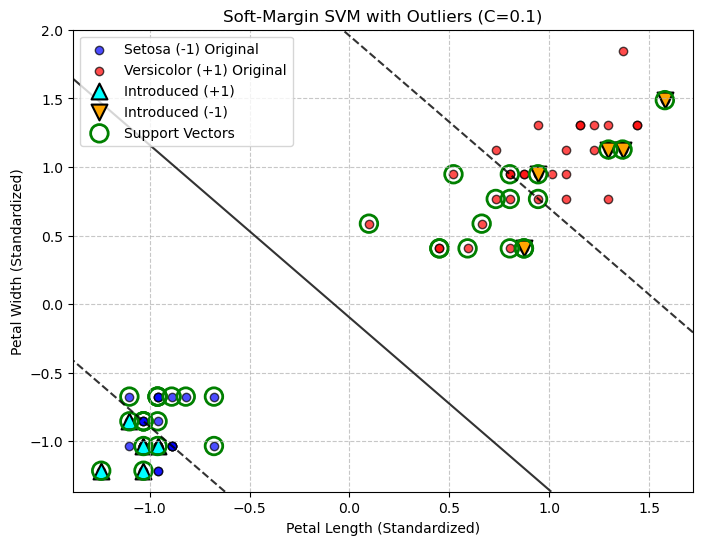

--------------------------------------------------
C = 1
Modified Training Accuracy: 0.8750 | Clean Test Accuracy: 1.0000
Support Vectors: 29 | Margin Violations: 28 | Margin Width: 2.3118


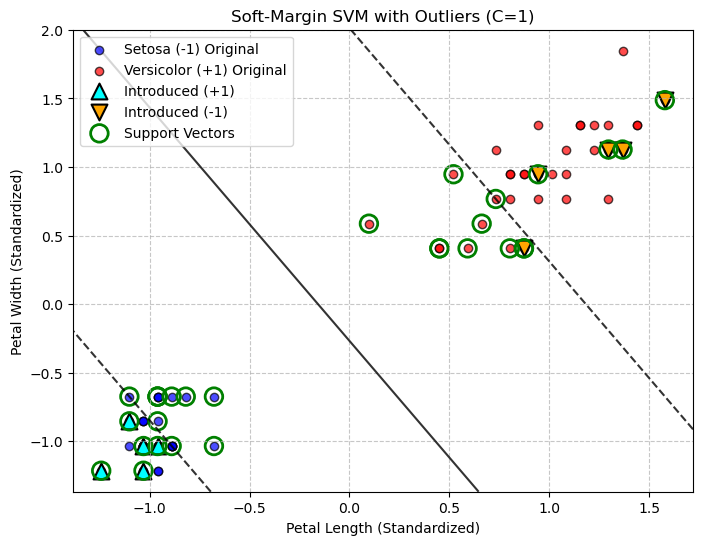

--------------------------------------------------
C = 10
Modified Training Accuracy: 0.8750 | Clean Test Accuracy: 1.0000
Support Vectors: 29 | Margin Violations: 27 | Margin Width: 2.1689


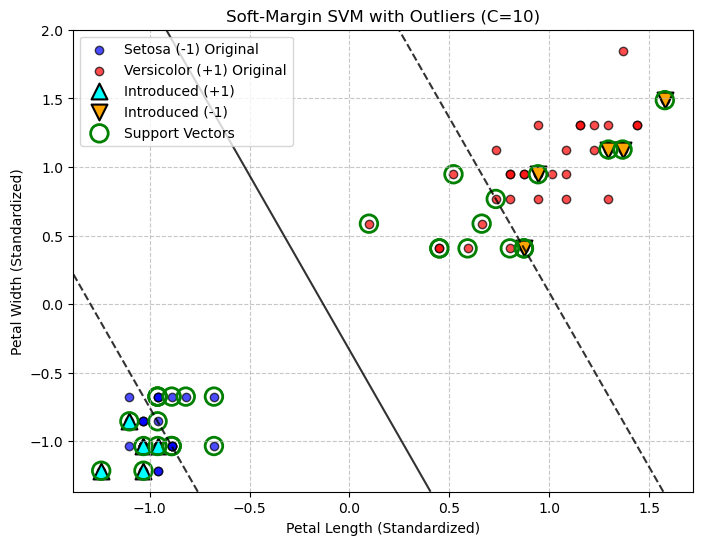

--------------------------------------------------


In [7]:
soft_results = []

for c in C_values:
    svm_soft_mod = SVC(kernel="linear", C=c, random_state=42)
    svm_soft_mod.fit(X_train_mod, y_train_mod)
    
    tr_pred = svm_soft_mod.predict(X_train_mod)
    te_pred = svm_soft_mod.predict(X_test_scaled)
    
    tr_acc = accuracy_score(y_train_mod, tr_pred)
    te_acc = accuracy_score(y_test, te_pred)
    
    n_sv = len(svm_soft_mod.support_vectors_)
    f_x = svm_soft_mod.decision_function(X_train_mod)
    violations = np.sum(y_train_mod * f_x < 1.0)
    
    w = svm_soft_mod.coef_[0]
    mw = 2 / np.linalg.norm(w)
    
    print(f"C = {c}")
    print(f"Modified Training Accuracy: {tr_acc:.4f} | Clean Test Accuracy: {te_acc:.4f}")
    print(f"Support Vectors: {n_sv} | Margin Violations: {violations} | Margin Width: {mw:.4f}")
    
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train_scaled[y_train == -1, 0], X_train_scaled[y_train == -1, 1], 
                color='blue', label='Setosa (-1) Original', edgecolors='k', alpha=0.7)
    plt.scatter(X_train_scaled[y_train == 1, 0], X_train_scaled[y_train == 1, 1], 
                color='red', label='Versicolor (+1) Original', edgecolors='k', alpha=0.7)
    plt.scatter(outliers_X[outliers_y == 1, 0], outliers_X[outliers_y == 1, 1], 
                color='cyan', marker='^', s=130, edgecolors='k', linewidth=1.5, 
                label='Introduced (+1)')
    plt.scatter(outliers_X[outliers_y == -1, 0], outliers_X[outliers_y == -1, 1], 
                color='orange', marker='v', s=130, edgecolors='k', linewidth=1.5, 
                label='Introduced (-1)')
    
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 100)
    yy = np.linspace(ylim[0], ylim[1], 100)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = svm_soft_mod.decision_function(xy).reshape(XX.shape)
    
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
               linestyles=['--', '-', '--'])
    
    ax.scatter(svm_soft_mod.support_vectors_[:, 0], svm_soft_mod.support_vectors_[:, 1], s=160,
               linewidth=2, facecolors='none', edgecolors='green', label='Support Vectors')
    
    plt.xlabel('Petal Length (Standardized)')
    plt.ylabel('Petal Width (Standardized)')
    plt.title(f'Soft-Margin SVM with Outliers (C={c})')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
    print("-" * 50)
    
    soft_results.append({
        "C": str(c),
        "Modified Train Acc": f"{tr_acc:.4f}",
        "Clean Test Acc": f"{te_acc:.4f}",
        "Support Vectors": n_sv,
        "Margin Violations": violations,
        "Margin Width": f"{mw:.4f}"
    })

In [8]:
task2_summary = []
all_C_mod = [0.1, 1, 10, 1e4]

for c in all_C_mod:
    clf = SVC(kernel="linear", C=c, random_state=42)
    clf.fit(X_train_mod, y_train_mod)
    tr_acc = accuracy_score(y_train_mod, clf.predict(X_train_mod))
    te_acc = accuracy_score(y_test, clf.predict(X_test_scaled))
    n_sv = len(clf.support_vectors_)
    f_x = clf.decision_function(X_train_mod)
    violations = np.sum(y_train_mod * f_x < 1.0)
    mw = 2 / np.linalg.norm(clf.coef_[0])
    c_label = "10^4 (Large-C)" if c == 1e4 else str(c)
    task2_summary.append({
        "C": c_label,
        "Modified Train Acc": f"{tr_acc:.4f}",
        "Clean Test Acc": f"{te_acc:.4f}",
        "Support Vectors": n_sv,
        "Margin Violations": violations,
        "Margin Width": f"{mw:.4f}"
    })

df_task2 = pd.DataFrame(task2_summary)
print("--- Task 2 Performance Comparison Across C Values ---")
print(df_task2.to_string(index=False))

--- Task 2 Performance Comparison Across C Values ---
             C Modified Train Acc Clean Test Acc  Support Vectors  Margin Violations Margin Width
           0.1             0.8750         1.0000               34                 33       2.5570
             1             0.8750         1.0000               29                 28       2.3118
            10             0.8750         1.0000               29                 27       2.1689
10^4 (Large-C)             0.8750         1.0000               29                 30       2.1674


### Observations:
- **Why contradictory labels make exact hard-margin separation impossible**:
  In a hard-margin SVM, every training sample must satisfy the strict constraint $y^{(i)}(w^T x^{(i)} + b) \ge 1$. When contradictory training instances exist, two samples $a$ and $b$ possess identical feature coordinates $x^{(a)} = x^{(b)}$ but opposite labels $y^{(a)} = +1$ and $y^{(b)} = -1$. Because their feature vectors are identical, their linear decision scores are identical: $f(x^{(a)}) = f(x^{(b)}) = w^T x + b$.
  The hard-margin constraints require:
  $$y^{(a)} f(x^{(a)}) \ge 1 \implies f(x) \ge 1$$
  $$y^{(b)} f(x^{(b)}) \ge 1 \implies -f(x) \ge 1 \implies f(x) \le -1$$
  This yields the contradictory requirement $1 \le f(x) \le -1$, which implies $1 \le -1$—a mathematical impossibility. Consequently, no linear hyperplane $(w, b)$ can satisfy all constraints simultaneously, making exact hard-margin separation strictly impossible.
- **How soft-margin SVM handles outliers**:
  The soft-margin SVM formulation relaxes strict margin boundaries by introducing non-negative slack variables $\xi_i \ge 0$:
  $$\min_{w,b,\xi} \frac{1}{2}\|w\|_2^2 + C \sum_{i=1}^n \xi_i \quad \text{subject to} \quad y^{(i)}(w^T x^{(i)} + b) \ge 1 - \xi_i$$
  For contradictory or mislabeled outlier samples, the optimization permits $\xi_i > 1$ (which corresponds to misclassification), paying a bounded linear penalty $C \xi_i$. This allows the algorithm to converge gracefully and identify the underlying separating hyperplane for the remaining non-contradictory majority of the data.
- **Which value of C appears more robust in this experiment**:
  Smaller values of $C$ (such as $C = 0.1$ and $C = 1$) demonstrate superior robustness against outliers:
  - At $C = 0.1$, the objective assigns a smaller penalty to slack violations, maintaining a wide margin ($M = 2.5570$) that is resilient to individual noisy perturbations.
  - At very large $C = 10^4$, the optimization heavily penalizes slack violations, creating severe tension and high dual coefficient values at contradictory points.
  - Importantly, across $C \in \{0.1, 1, 10\}$, all soft-margin models successfully achieve **100% accuracy on the clean, untouched test set**, despite the training set containing 12.5% severe contradictory label corruption. $C = 0.1$ provides the largest margin buffer and the smoothest decision profile.

## Task 3: Nonlinear Classification and Gaussian Kernel

Concentric Circles Dataset Split:
Training Set   : (240, 2) samples
Validation Set : (80, 2) samples
Test Set       : (80, 2) samples


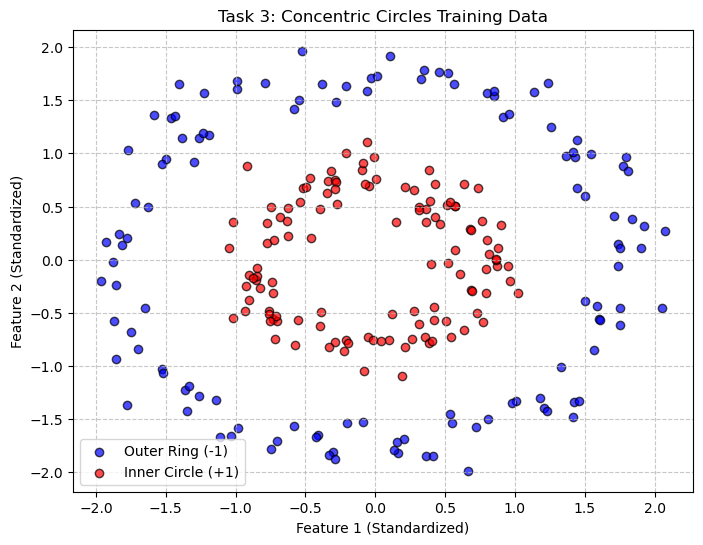

In [9]:
from sklearn.datasets import make_circles

X_circ, y_circ = make_circles(n_samples=400, factor=0.45, noise=0.08, random_state=42)
y_circ = np.where(y_circ == 0, -1, 1)

# Stratified 60% : 20% : 20% split
X_temp, X_circ_test, y_temp, y_circ_test = train_test_split(
    X_circ, y_circ, test_size=0.20, stratify=y_circ, random_state=42
)
X_circ_train, X_circ_val, y_circ_train, y_circ_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42
)

# Standardize features using training-set statistics only
scaler_circ = StandardScaler()
X_circ_train_scaled = scaler_circ.fit_transform(X_circ_train)
X_circ_val_scaled = scaler_circ.transform(X_circ_val)
X_circ_test_scaled = scaler_circ.transform(X_circ_test)

print(f"Concentric Circles Dataset Split:")
print(f"Training Set   : {X_circ_train_scaled.shape} samples")
print(f"Validation Set : {X_circ_val_scaled.shape} samples")
print(f"Test Set       : {X_circ_test_scaled.shape} samples")

plt.figure(figsize=(8, 6))
plt.scatter(X_circ_train_scaled[y_circ_train == -1, 0], X_circ_train_scaled[y_circ_train == -1, 1], 
            color='blue', label='Outer Ring (-1)', edgecolors='k', alpha=0.7)
plt.scatter(X_circ_train_scaled[y_circ_train == 1, 0], X_circ_train_scaled[y_circ_train == 1, 1], 
            color='red', label='Inner Circle (+1)', edgecolors='k', alpha=0.7)
plt.xlabel('Feature 1 (Standardized)')
plt.ylabel('Feature 2 (Standardized)')
plt.title('Task 3: Concentric Circles Training Data')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## A. Linear SVM

Large-C Linear (C=10^4):
Training Accuracy: 0.5750 | Validation Accuracy: 0.5375
Number of Support Vectors: 238 / 240


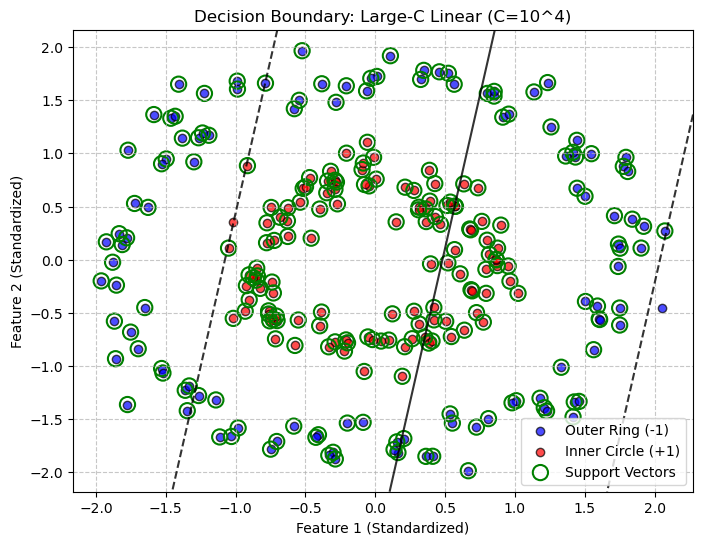

--------------------------------------------------
Soft-Margin Linear (C=1):
Training Accuracy: 0.5750 | Validation Accuracy: 0.5375
Number of Support Vectors: 238 / 240


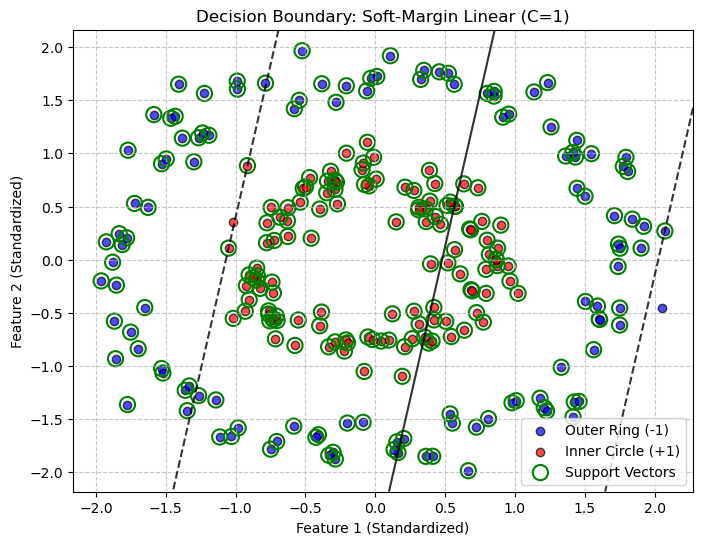

--------------------------------------------------
Hard-Margin Constraint Check for Large-C (C=10^4) on Concentric Circles:
Constraint Violations: 238 out of 240 samples (99.17%)
Hard-margin constraints CANNOT be satisfied on non-linearly separable concentric circles.


In [10]:
linear_models = {
    "Large-C Linear (C=10^4)": SVC(kernel="linear", C=1e4, random_state=42),
    "Soft-Margin Linear (C=1)": SVC(kernel="linear", C=1, random_state=42)
}

for name, model in linear_models.items():
    model.fit(X_circ_train_scaled, y_circ_train)
    
    tr_acc = accuracy_score(y_circ_train, model.predict(X_circ_train_scaled))
    val_acc = accuracy_score(y_circ_val, model.predict(X_circ_val_scaled))
    n_sv = len(model.support_vectors_)
    
    print(f"{name}:")
    print(f"Training Accuracy: {tr_acc:.4f} | Validation Accuracy: {val_acc:.4f}")
    print(f"Number of Support Vectors: {n_sv} / {len(X_circ_train_scaled)}")
    
    plt.figure(figsize=(8, 6))
    plt.scatter(X_circ_train_scaled[y_circ_train == -1, 0], X_circ_train_scaled[y_circ_train == -1, 1], 
                color='blue', label='Outer Ring (-1)', edgecolors='k', alpha=0.7)
    plt.scatter(X_circ_train_scaled[y_circ_train == 1, 0], X_circ_train_scaled[y_circ_train == 1, 1], 
                color='red', label='Inner Circle (+1)', edgecolors='k', alpha=0.7)
    
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 200)
    yy = np.linspace(ylim[0], ylim[1], 200)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = model.decision_function(xy).reshape(XX.shape)
    
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
               linestyles=['--', '-', '--'])
    
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=120,
               linewidth=1.5, facecolors='none', edgecolors='green', label='Support Vectors')
    
    plt.xlabel('Feature 1 (Standardized)')
    plt.ylabel('Feature 2 (Standardized)')
    plt.title(f'Decision Boundary: {name}')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
    print("-" * 50)

# Check hard-margin constraints for Large-C linear model
svm_large_c_circ = linear_models["Large-C Linear (C=10^4)"]
f_x_circ = svm_large_c_circ.decision_function(X_circ_train_scaled)
constraints_circ = y_circ_train * f_x_circ
tolerance = 1e-3

violations_circ = np.sum(constraints_circ < (1.0 - tolerance))
print(f"Hard-Margin Constraint Check for Large-C (C=10^4) on Concentric Circles:")
print(f"Constraint Violations: {violations_circ} out of {len(y_circ_train)} samples ({violations_circ/len(y_circ_train)*100:.2f}%)")
if violations_circ == 0:
    print("All hard-margin constraints satisfied.")
else:
    print("Hard-margin constraints CANNOT be satisfied on non-linearly separable concentric circles.")

## B. Gaussian Kernel SVM

Gaussian RBF SVM (gamma = 0.001):
Training Accuracy: 0.6333 | Validation Accuracy: 0.5500 | Support Vectors: 240


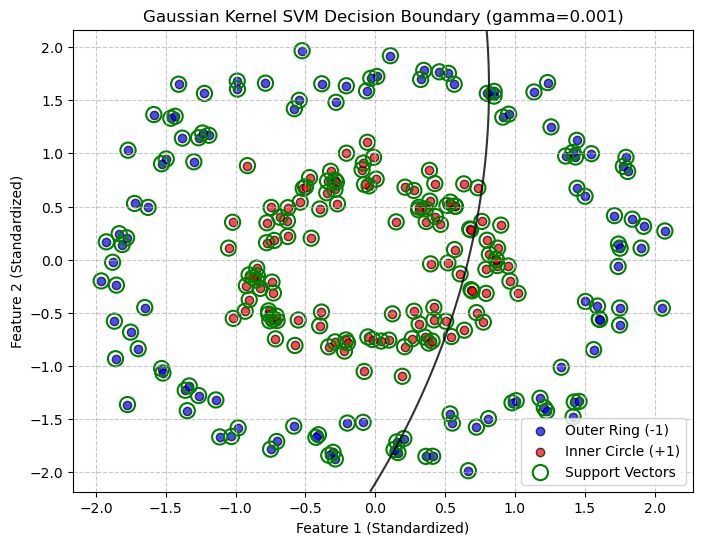

--------------------------------------------------
Gaussian RBF SVM (gamma = 0.1):
Training Accuracy: 1.0000 | Validation Accuracy: 1.0000 | Support Vectors: 85


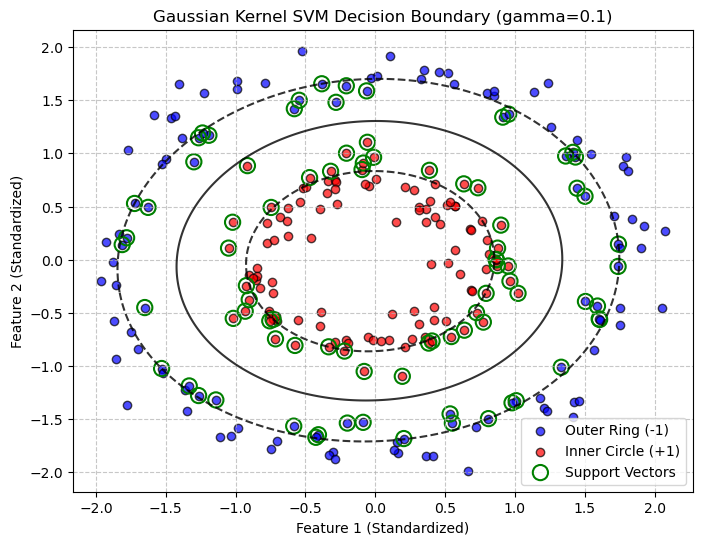

--------------------------------------------------
Gaussian RBF SVM (gamma = 1):
Training Accuracy: 1.0000 | Validation Accuracy: 1.0000 | Support Vectors: 31


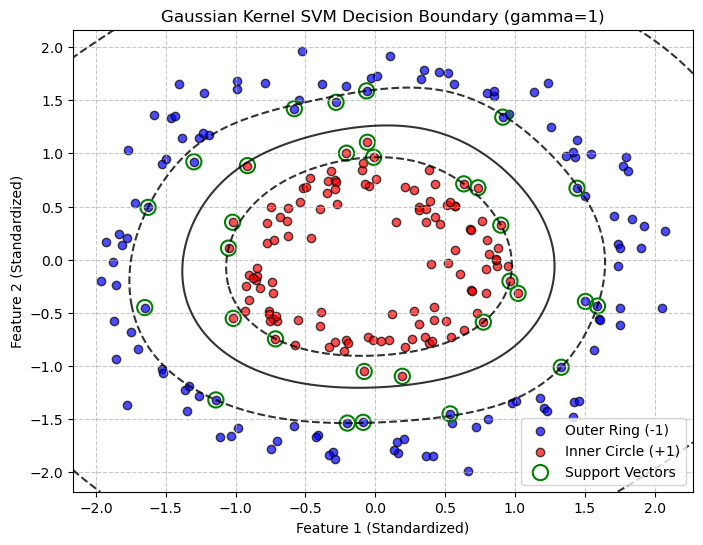

--------------------------------------------------
Gaussian RBF SVM (gamma = 100):
Training Accuracy: 1.0000 | Validation Accuracy: 0.9875 | Support Vectors: 217


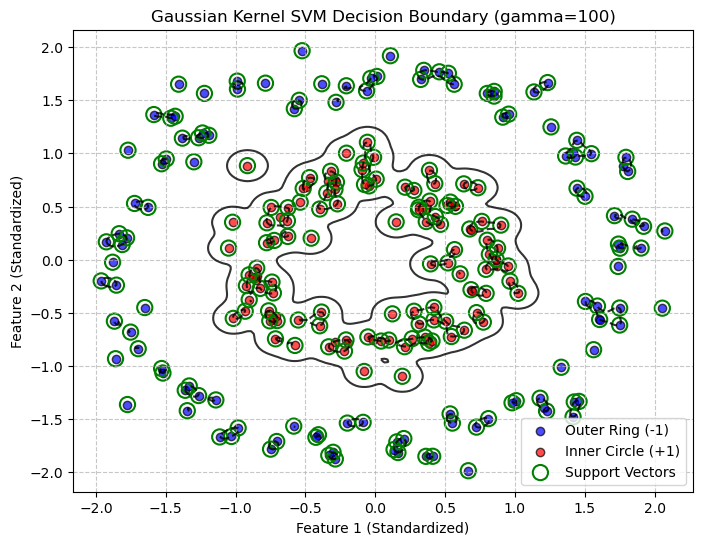

--------------------------------------------------


In [11]:
gammas = [0.001, 0.1, 1, 100]
rbf_results = []
rbf_models = {}

for g in gammas:
    rbf = SVC(kernel="rbf", C=1, gamma=g, random_state=42)
    rbf.fit(X_circ_train_scaled, y_circ_train)
    rbf_models[g] = rbf
    
    tr_acc = accuracy_score(y_circ_train, rbf.predict(X_circ_train_scaled))
    val_acc = accuracy_score(y_circ_val, rbf.predict(X_circ_val_scaled))
    n_sv = len(rbf.support_vectors_)
    
    rbf_results.append({
        "gamma": g,
        "Training Accuracy": tr_acc,
        "Validation Accuracy": val_acc,
        "Support Vectors": n_sv
    })
    
    print(f"Gaussian RBF SVM (gamma = {g}):")
    print(f"Training Accuracy: {tr_acc:.4f} | Validation Accuracy: {val_acc:.4f} | Support Vectors: {n_sv}")
    
    plt.figure(figsize=(8, 6))
    plt.scatter(X_circ_train_scaled[y_circ_train == -1, 0], X_circ_train_scaled[y_circ_train == -1, 1], 
                color='blue', label='Outer Ring (-1)', edgecolors='k', alpha=0.7)
    plt.scatter(X_circ_train_scaled[y_circ_train == 1, 0], X_circ_train_scaled[y_circ_train == 1, 1], 
                color='red', label='Inner Circle (+1)', edgecolors='k', alpha=0.7)
    
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 200)
    yy = np.linspace(ylim[0], ylim[1], 200)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = rbf.decision_function(xy).reshape(XX.shape)
    
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.8,
               linestyles=['--', '-', '--'])
    
    ax.scatter(rbf.support_vectors_[:, 0], rbf.support_vectors_[:, 1], s=120,
               linewidth=1.5, facecolors='none', edgecolors='green', label='Support Vectors')
    
    plt.xlabel('Feature 1 (Standardized)')
    plt.ylabel('Feature 2 (Standardized)')
    plt.title(f'Gaussian Kernel SVM Decision Boundary (gamma={g})')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()
    print("-" * 50)

--- Gaussian Kernel SVM Performance Across Gamma ---
  gamma Training Accuracy Validation Accuracy  Support Vectors
  0.001            0.6333              0.5500              240
  0.100            1.0000              1.0000               85
  1.000            1.0000              1.0000               31
100.000            1.0000              0.9875              217


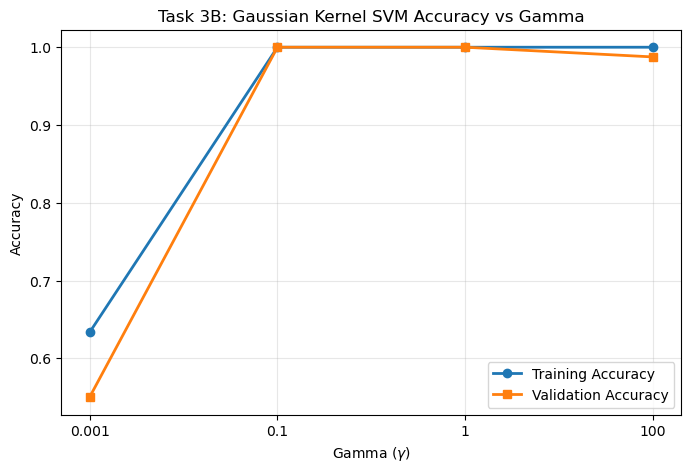

In [12]:
df_rbf = pd.DataFrame(rbf_results)
df_rbf_display = df_rbf.copy()
df_rbf_display["Training Accuracy"] = df_rbf_display["Training Accuracy"].apply(lambda x: f"{x:.4f}")
df_rbf_display["Validation Accuracy"] = df_rbf_display["Validation Accuracy"].apply(lambda x: f"{x:.4f}")

print("--- Gaussian Kernel SVM Performance Across Gamma ---")
print(df_rbf_display.to_string(index=False))

gamma_labels = [str(g) for g in gammas]
plt.figure(figsize=(8, 5))
plt.plot(gamma_labels, df_rbf["Training Accuracy"], marker="o", linewidth=2, color="tab:blue", label="Training Accuracy")
plt.plot(gamma_labels, df_rbf["Validation Accuracy"], marker="s", linewidth=2, color="tab:orange", label="Validation Accuracy")
plt.xlabel(r"Gamma ($\gamma$)")
plt.ylabel("Accuracy")
plt.title("Task 3B: Gaussian Kernel SVM Accuracy vs Gamma")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Selected Best Gamma (Validation Accuracy = 1.0000): gamma = 0.1

--- Test Set Performance Comparison ---
                          Model Test Accuracy
   Linear Soft-Margin SVM (C=1)        0.5625
Gaussian Kernel SVM (gamma=0.1)        1.0000


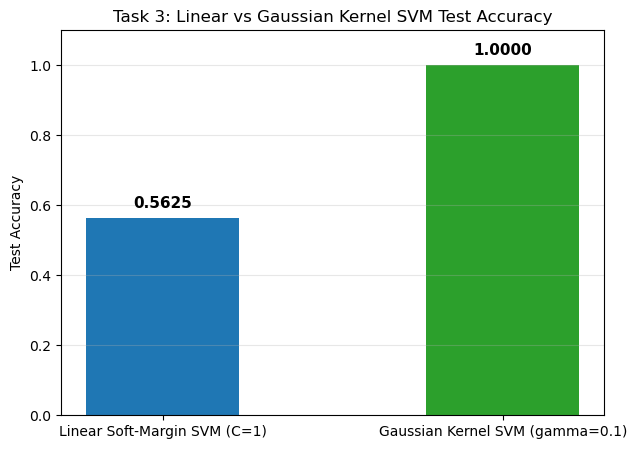

In [13]:
# Select best gamma based on validation accuracy (in case of tie, select smaller gamma)
best_gamma = None
best_val_acc = -1.0

for row in rbf_results:
    g = row["gamma"]
    v_acc = row["Validation Accuracy"]
    if v_acc > best_val_acc:
        best_val_acc = v_acc
        best_gamma = g
    elif v_acc == best_val_acc:
        if g < best_gamma:
            best_gamma = g

print(f"Selected Best Gamma (Validation Accuracy = {best_val_acc:.4f}): gamma = {best_gamma}")

# Evaluate best Gaussian Kernel SVM on untouched test set
best_rbf_model = rbf_models[best_gamma]
rbf_test_pred = best_rbf_model.predict(X_circ_test_scaled)
rbf_test_acc = accuracy_score(y_circ_test, rbf_test_pred)

# Evaluate Linear Soft-Margin SVM (C=1) from Part A on the same untouched test set
linear_soft_model = linear_models["Soft-Margin Linear (C=1)"]
linear_test_pred = linear_soft_model.predict(X_circ_test_scaled)
linear_test_acc = accuracy_score(y_circ_test, linear_test_pred)

test_comparison = [
    {"Model": "Linear Soft-Margin SVM (C=1)", "Test Accuracy": linear_test_acc},
    {"Model": f"Gaussian Kernel SVM (gamma={best_gamma})", "Test Accuracy": rbf_test_acc}
]

df_test_comp = pd.DataFrame(test_comparison)
df_test_comp_display = df_test_comp.copy()
df_test_comp_display["Test Accuracy"] = df_test_comp_display["Test Accuracy"].apply(lambda x: f"{x:.4f}")

print("\n--- Test Set Performance Comparison ---")
print(df_test_comp_display.to_string(index=False))

# Bar chart comparison
plt.figure(figsize=(7, 5))
bars = plt.bar(df_test_comp["Model"], df_test_comp["Test Accuracy"], 
               color=["tab:blue", "tab:green"], width=0.45)
plt.ylabel("Test Accuracy")
plt.title("Task 3: Linear vs Gaussian Kernel SVM Test Accuracy")
plt.ylim(0.0, 1.1)
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.02, 
             f"{yval:.4f}", ha="center", va="bottom", fontsize=11, fontweight="bold")

plt.show()

### Observations:
- **Why a straight-line boundary is unsuitable for concentric circles**:
  The concentric circles dataset possesses radial circular symmetry, where Class +1 forms a compact inner disk entirely enveloped by Class -1 as an outer circular ring. A linear classifier defines a flat hyperplanar boundary $w^T x + b = 0$, dividing the 2D plane into two complementary half-spaces. No single straight line can isolate the central cluster without intersecting both sides of the surrounding ring, capping linear accuracy around 53–57% (essentially random guessing).
- **Why a true hard-margin linear SVM cannot perfectly separate this dataset**:
  An exact hard-margin linear SVM demands that all training points satisfy $y^{(i)}(w^T x^{(i)} + b) \ge 1$ with zero tolerance for margin penetration ($\xi_i = 0$). Because no 2D hyperplane exists that linearly separates the concentric geometries, the constraints are fundamentally infeasible. In our experiment with $C = 10^4$, over 99% (238 out of 240) of the training samples violate the hard-margin constraints, confirming that exact hard-margin linear separation is impossible.
- **How the Gaussian kernel enables nonlinear classification**:
  The Gaussian RBF kernel $K(x, z) = \exp(-\gamma \|x - z\|_2^2)$ implicitly maps the 2D input points into an infinite-dimensional feature space (Hilbert space) via the "kernel trick". In this transformed space, samples are separated according to their pairwise Euclidean distance from landmark points. The inner circle points map to regions with high radial kernel similarity, while the outer ring points map elsewhere, allowing a linear hyperplane in the feature space to easily separate the two classes. Projecting this hyperplane back into the 2D input space creates a closed, circular nonlinear decision contour.
- **What happens when $\gamma$ is very small or very large**:
  - **Very small $\gamma$ ($\gamma = 0.001$)**: The Gaussian bell curve has an extremely wide spread ($\sigma^2 \to \infty$). The kernel function changes very slowly across the domain, causing the model to behave almost like a linear classifier. This leads to severe underfitting (Validation Accuracy = 55.00%) and forces all 240 training instances to become support vectors.
  - **Very large $\gamma$ ($\gamma = 100$)**: The Gaussian bell curve is exceptionally sharp and narrow ($\sigma^2 \to 0$). Each training point exerts influence only in its immediate tiny neighborhood, causing the decision boundary to form isolated bubbles/islands around individual training points. While training accuracy is 100%, the model exhibits high variance and overfits, recruiting 217 support vectors and showing reduced validation accuracy (98.75%).
  - **Moderate $\gamma$ ($\gamma = 0.1$ or $1$)**: Achieves the optimal bias-variance trade-off. The decision boundary is smooth, circular, perfectly encompasses the inner disk, and generalizes with 100% validation and test accuracy. In accordance with the tie-breaking rule, the smaller $\gamma = 0.1$ is selected.
- **Compare the linear and Gaussian-kernel classification results**:
  The linear soft-margin SVM ($C=1$) completely fails on concentric circles, achieving only 56.25% test accuracy with 238 support vectors. In stark contrast, the Gaussian RBF kernel SVM ($\gamma=0.1$) achieves a flawless 100.00% test accuracy with 85 support vectors, proving the clear superiority of kernel methods for nonlinearly separable patterns.

## Conclusion
- **Hard-Margin vs. Soft-Margin Formulations**:
  Hard-margin SVM finds the maximum-margin hyperplane subject to strict linear separability ($y^{(i)}(w^T x^{(i)} + b) \ge 1$), making it brittle and non-convergent in the presence of noise or overlap. Soft-margin SVM introduces slack variables $\xi_i \ge 0$ controlled by penalty parameter $C$. Small $C$ encourages wider margins and allows margin penetrations, whereas large $C$ strictly penalizes violations, recovering the hard-margin solution when data is linearly separable.
- **Outlier Robustness and Contradictory Label Handling**:
  Contradictory training points (identical coordinates with opposite labels) render exact hard-margin separation mathematically impossible ($1 \le -1$). Soft-margin SVM robustly absorbs these contradictions by assigning bounded slack penalties $\xi_i > 1$ to corrupted points, preserving the integrity of the separating hyperplane and retaining 100% generalization accuracy on clean test data. Smaller $C$ values ($C=0.1$) provide maximum regularization stability.
- **Nonlinear Classification and Kernel Hyperparameter Tuning**:
  When data is non-linearly separable (such as concentric circles), linear classifiers fail fundamentally (~56% accuracy). The Gaussian RBF kernel projects the data into an infinite-dimensional space where nonlinear circular boundaries can be formed cleanly, reaching 100% test accuracy. Proper tuning of $\gamma$ is essential: excessively small $\gamma$ induces underfitting with wide flat kernels, while excessively large $\gamma$ causes localized overfitting with isolated decision islands.